# Lab 1: Handling Missing Values in the Titanic Dataset

**Name:** Yashodhara Heggade  
**Reg:** 2427010154  
**Sec:** C/ Batch 1

## Aim
Take a sample dataset, identify missing values, and handle them using: (1) mean imputation, (2) removing rows with missing values, and (3) K-Nearest Neighbors (KNN) imputation.

## Dataset: Kaggle Titanic


## 1. Import libraries


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer

sns.set_theme(style="whitegrid")

## 2. Load and inspect the dataset


In [2]:
csv_candidates = [
    Path("/kaggle/input/titanic/train.csv"),
    Path("train.csv"),
    Path("data/train.csv")
]
csv_path = next((path for path in csv_candidates if path.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        "Could not find train.csv. Download it from the Kaggle Titanic data page and "
        "place it beside this notebook (or in ./data/train.csv). On Kaggle, attach the "
        "dataset so it is available under /kaggle/input/titanic/."
    )

df = pd.read_csv(csv_path)
print("Loaded file:", csv_path)
print("Dataset shape:", df.shape)
df.head()

Loaded file: train.csv
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Inspect data types and missing-value counts
print("Column data types:")
print(df.dtypes)
print("\nMissing values per column:")
missing_counts = df.isnull().sum().sort_values(ascending=False)
display(missing_counts.to_frame(name="Missing values"))

Column data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Missing values per column:


,Missing values
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


## 3. Visualize missing values


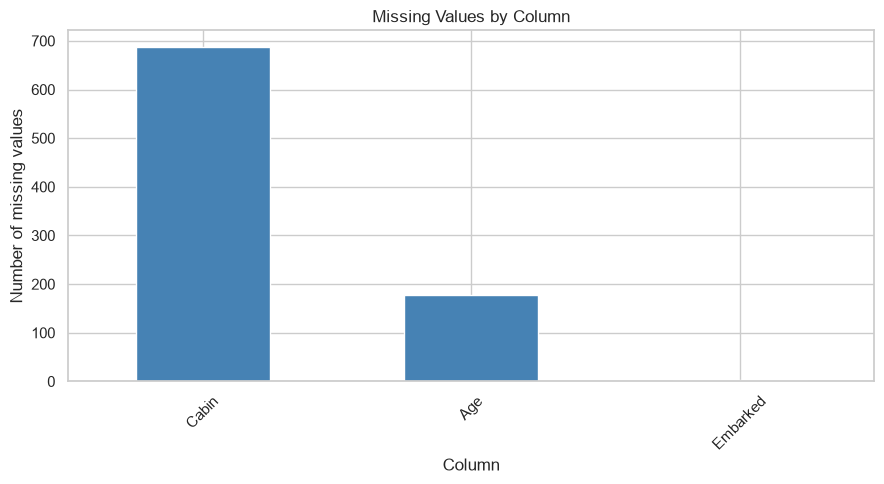

In [4]:
missing_counts[missing_counts > 0].plot(kind="bar", figsize=(9, 5), color="steelblue")
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of missing values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Choose numerical features for imputation



In [5]:
numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
print("Numerical predictors used:", numeric_features)
print("\nMissing values in selected features before imputation:")
print(df[numeric_features].isnull().sum())

Numerical predictors used: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Missing values in selected features before imputation:
Pclass      0
Age       177
SibSp       0
Parch       0
Fare        0
dtype: int64


## 5. Method 1: Mean imputation



In [6]:
mean_df = df.copy()

for column in numeric_features:
    column_mean = mean_df[column].mean()
    mean_df[column] = mean_df[column].fillna(column_mean)
    print(f"Filled missing {column} values with mean: {column_mean:.2f}")

print("\nRemaining missing values in selected numerical features:")
print(mean_df[numeric_features].isnull().sum())

Filled missing Pclass values with mean: 2.31
Filled missing Age values with mean: 29.70
Filled missing SibSp values with mean: 0.52
Filled missing Parch values with mean: 0.38
Filled missing Fare values with mean: 32.20

Remaining missing values in selected numerical features:
Pclass    0
Age       0
SibSp     0
Parch     0
Fare      0
dtype: int64


## 6. Method 2: Remove rows with missing values



In [7]:
dropped_df = df.dropna().copy()

print("Original number of rows:", len(df))
print("Rows after dropping any row with missing values:", len(dropped_df))
print("Rows removed:", len(df) - len(dropped_df))
print("Percentage of rows retained:", round(100 * len(dropped_df) / len(df), 2), "%")

Original number of rows: 891
Rows after dropping any row with missing values: 183
Rows removed: 708
Percentage of rows retained: 20.54 %


## 7. Method 3: K-Nearest Neighbors (KNN) imputation



In [8]:
# Standardize columns so large-scale features do not dominate distance
knn_df = df.copy()
feature_means = knn_df[numeric_features].mean()
feature_stds = knn_df[numeric_features].std().replace(0, 1)
scaled_features = (knn_df[numeric_features] - feature_means) / feature_stds

knn_imputer = KNNImputer(n_neighbors=5)
imputed_scaled = knn_imputer.fit_transform(scaled_features)

knn_df[numeric_features] = pd.DataFrame(
    imputed_scaled, columns=numeric_features, index=knn_df.index
) * feature_stds + feature_means

print("Remaining missing values in selected numerical features:")
print(knn_df[numeric_features].isnull().sum())

Remaining missing values in selected numerical features:
Pclass    0
Age       0
SibSp     0
Parch     0
Fare      0
dtype: int64


## 8. Compare the methods



In [9]:
comparison = pd.DataFrame({
    "Original": [len(df), int(df[numeric_features].isnull().sum().sum())],
    "Mean imputation": [len(mean_df), int(mean_df[numeric_features].isnull().sum().sum())],
    "Drop incomplete rows": [len(dropped_df), int(dropped_df[numeric_features].isnull().sum().sum())],
    "KNN imputation": [len(knn_df), int(knn_df[numeric_features].isnull().sum().sum())]
}, index=["Rows remaining", "Missing numerical values remaining"])
comparison

,Original,Mean imputation,Drop incomplete rows,KNN imputation
Rows remaining,891,891,183,891
Missing numerical values remaining,177,0,0,0


## 9. Compare Age distributions



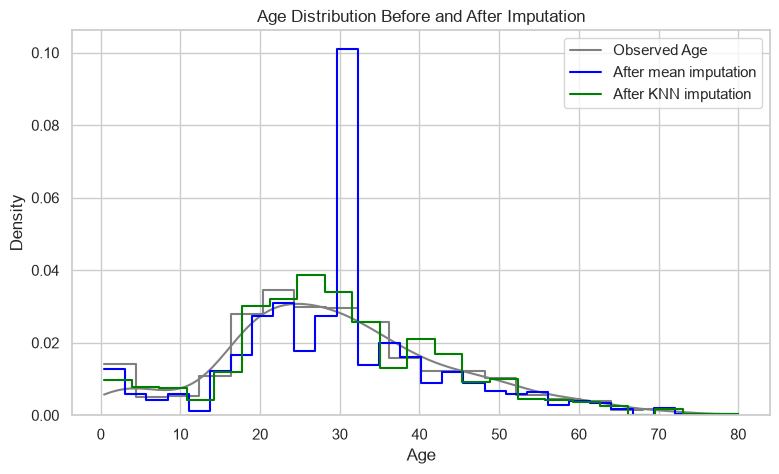

In [10]:
age_comparison = pd.DataFrame({
    "Original observed ages": df["Age"].dropna(),
    "Mean imputed ages": mean_df["Age"],
    "KNN imputed ages": knn_df["Age"]
})

plt.figure(figsize=(9, 5))
sns.histplot(age_comparison["Original observed ages"], color="gray",
             label="Observed Age", kde=True, stat="density",
             element="step", fill=False)
sns.histplot(mean_df["Age"], color="blue", label="After mean imputation",
             stat="density", element="step", fill=False)
sns.histplot(knn_df["Age"], color="green", label="After KNN imputation",
             stat="density", element="step", fill=False)
plt.title("Age Distribution Before and After Imputation")
plt.xlabel("Age")
plt.ylabel("Density")
plt.legend()
plt.show()